XGBoost not available, skipping...
CatBoost not available, skipping...
Loaded preprocessed data
COMPREHENSIVE MACHINE LEARNING ANALYSIS
MULTIPLE MODELS WITH CLASS IMBALANCE TECHNIQUES

1. DATA PREPARATION
----------------------------------------
Features shape: (161507, 50)
Target shape: (161507,)

Class distribution:
Class 0 (Assisted): 107548 (66.59%)
Class 1 (Unassisted): 53959 (33.41%)

Training set: (113054, 50)
Testing set: (48453, 50)

2. CLASS IMBALANCE TECHNIQUES
----------------------------------------
Testing imbalance techniques with Logistic Regression...

No Sampling:
  Resampled shape: (113054, 50)
  Class distribution: [75283 37771]
  Accuracy: 0.7944
  F1-Score: 0.6452
  ROC-AUC: 0.8384

Random OverSampler:
  Resampled shape: (150566, 50)
  Class distribution: [75283 75283]
  Accuracy: 0.7702
  F1-Score: 0.6751
  ROC-AUC: 0.8386

Random UnderSampler:
  Resampled shape: (75542, 50)
  Class distribution: [37771 37771]
  Accuracy: 0.7704
  F1-Score: 0.6757
  ROC-AUC: 0.83

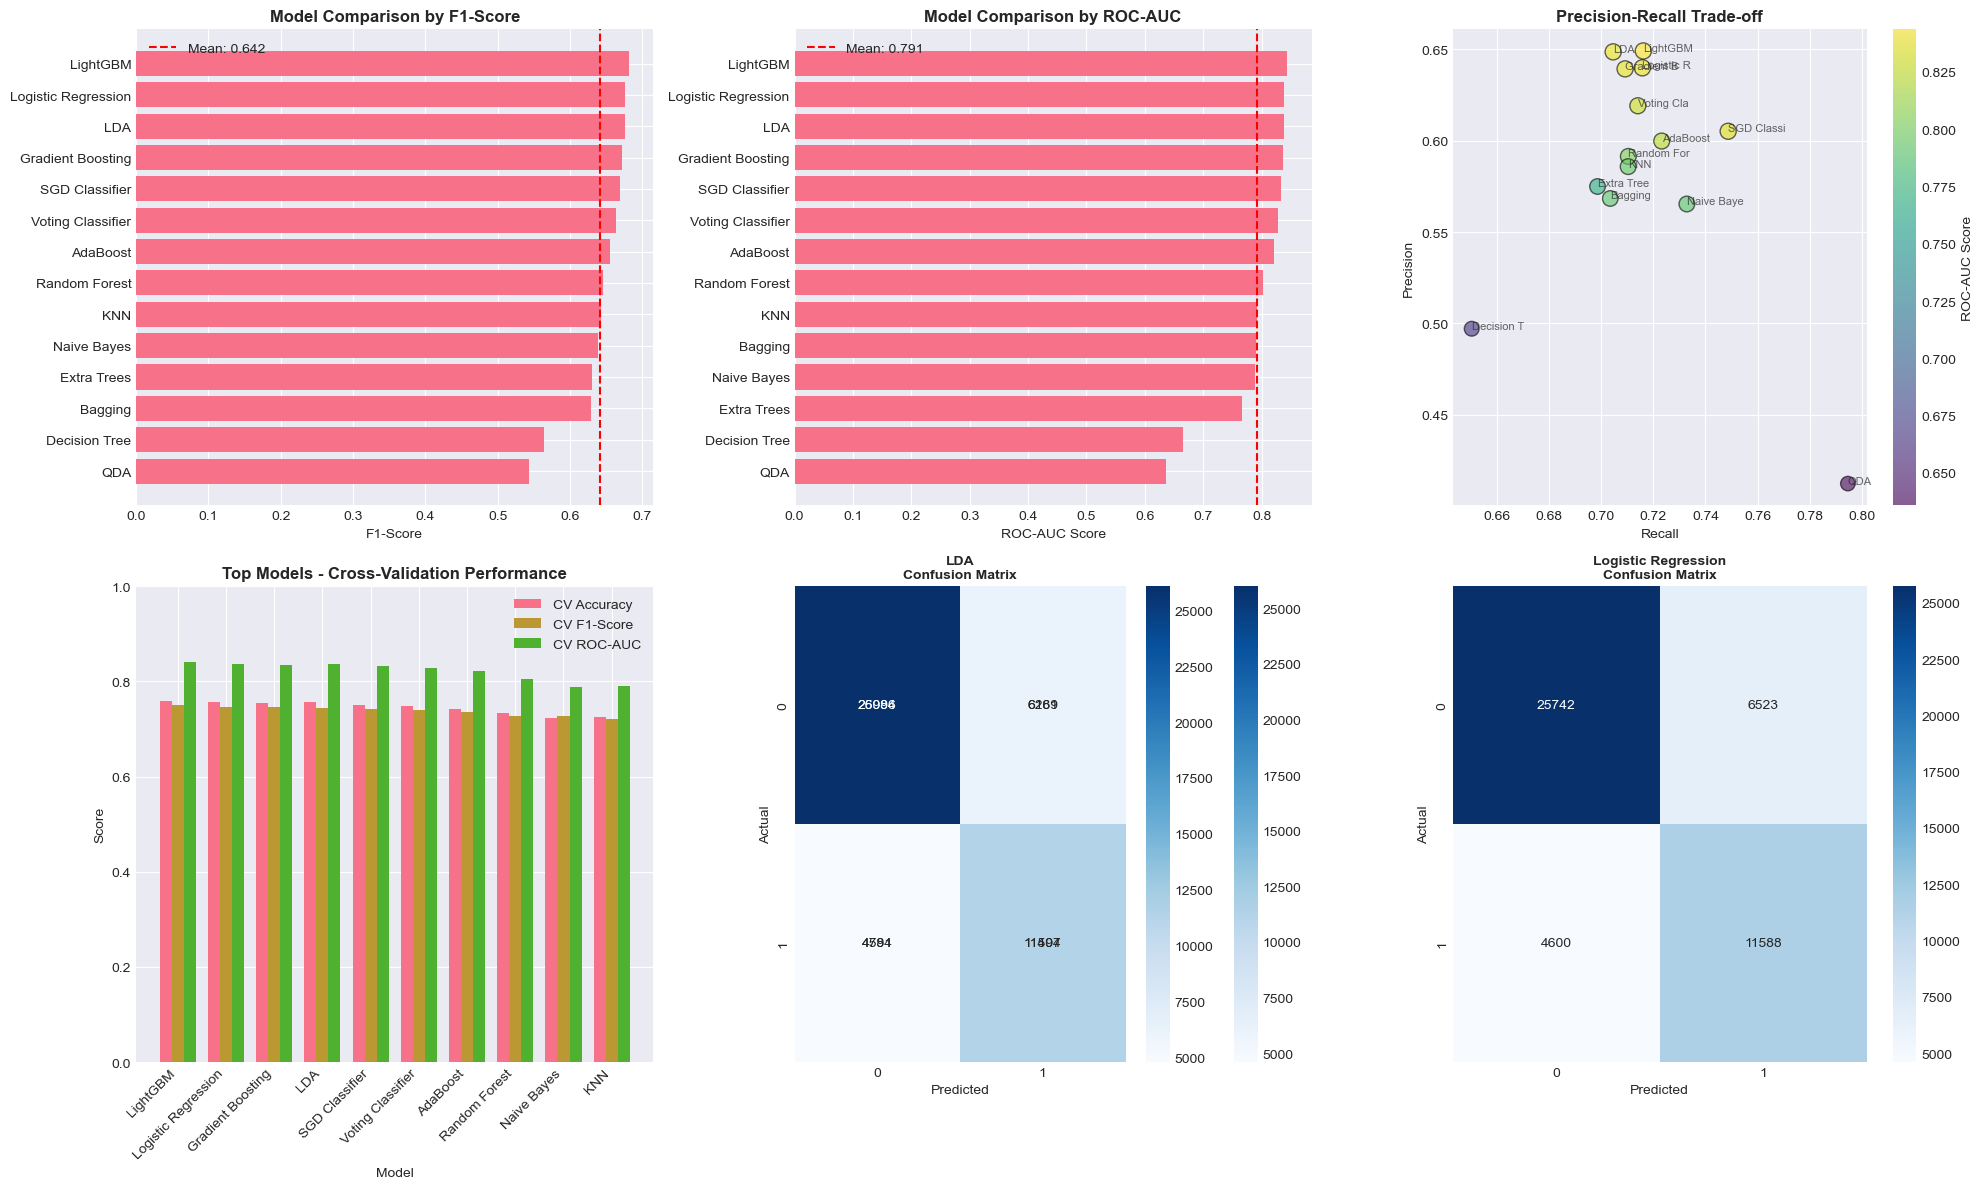


6. ROC CURVES COMPARISON
[LightGBM] [Info] Number of positive: 37771, number of negative: 37771
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.017082 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 149
[LightGBM] [Info] Number of data points in the train set: 75542, number of used features: 48
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


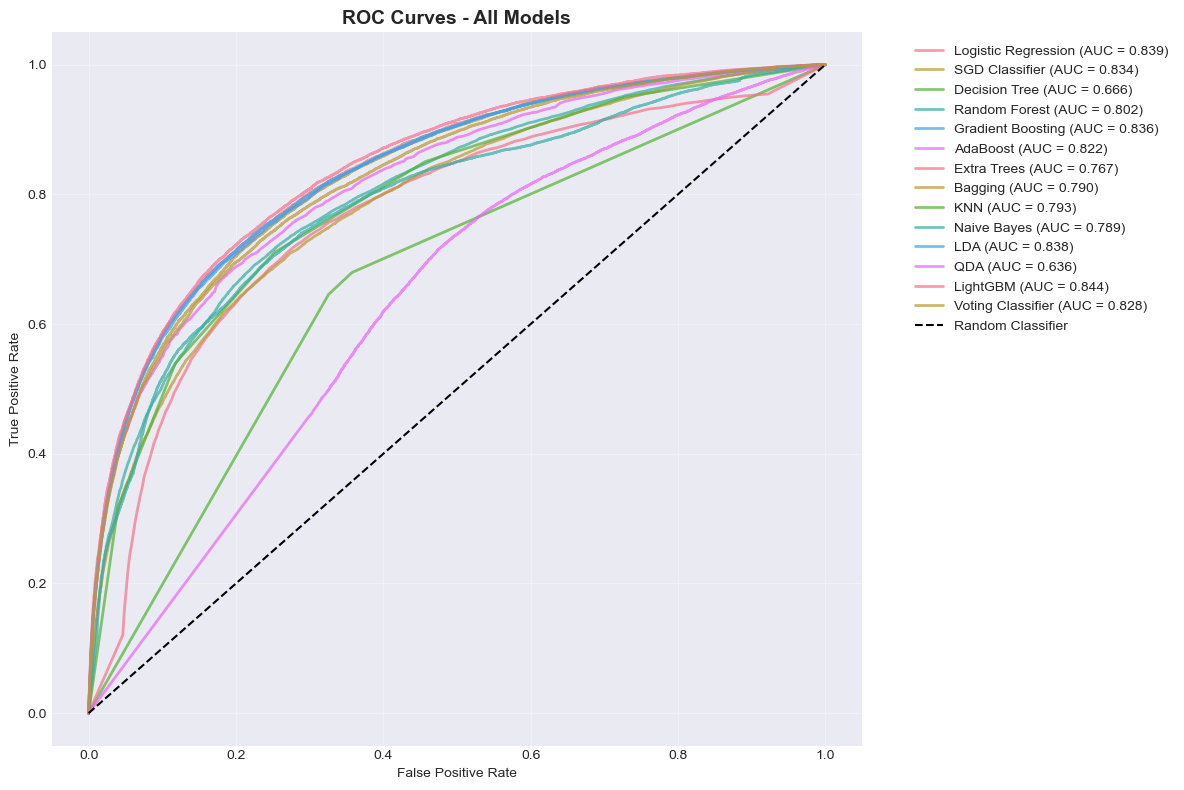


7. PRECISION-RECALL CURVES
[LightGBM] [Info] Number of positive: 37771, number of negative: 37771
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014007 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 149
[LightGBM] [Info] Number of data points in the train set: 75542, number of used features: 48
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


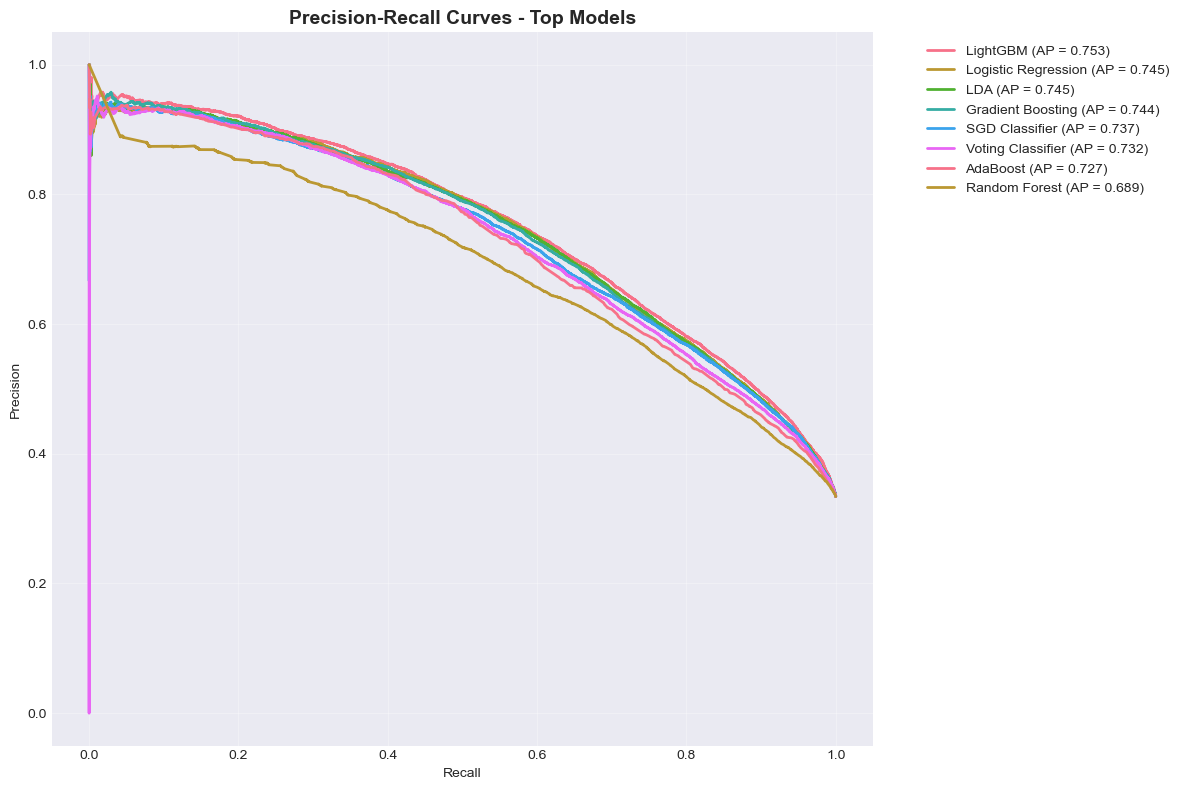


8. FEATURE IMPORTANCE ANALYSIS


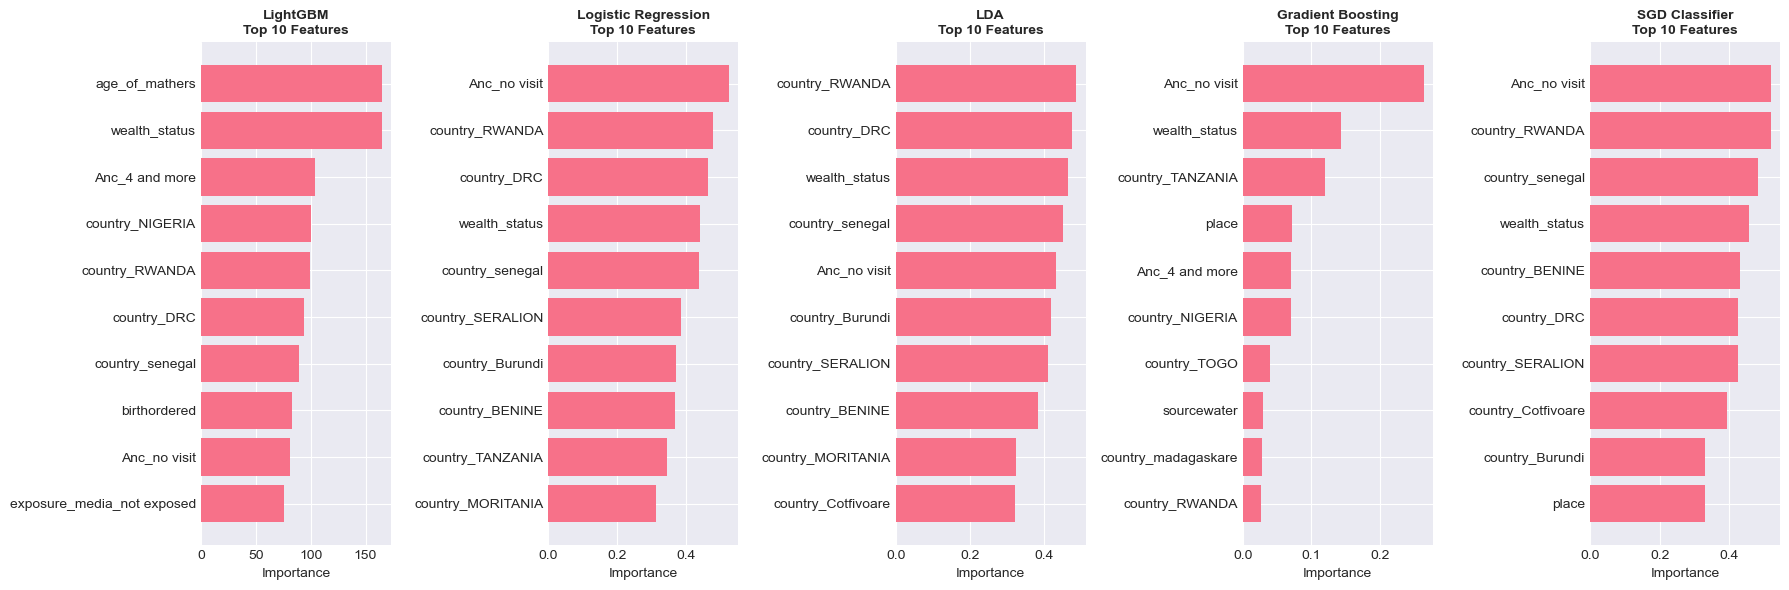


9. HYPERPARAMETER TUNING FOR BEST MODEL
Best model: LightGBM

10. FINAL SUMMARY AND RECOMMENDATIONS

COMPREHENSIVE MACHINE LEARNING ANALYSIS SUMMARY

DATASET INFORMATION:
- Total samples: 161,507
- Features: 50
- Target classes: 0 (Assisted), 1 (Unassisted)
- Class distribution: 107,548 (66.6%) assisted, 
                     53,959 (33.4%) unassisted

PREPROCESSING:
- Imbalance technique used: Random UnderSampler
- Features scaled using StandardScaler
- Train-test split: 70%-30% (stratified)

MODEL PERFORMANCE:

TOP 5 MODELS BY F1-SCORE:

1. LightGBM
   - F1-Score: 0.6810
   - Accuracy: 0.7758
   - Precision: 0.6491
   - Recall: 0.7162
   - ROC-AUC: 0.8436
   - CV F1-Score: 0.7495

2. Logistic Regression
   - F1-Score: 0.6757
   - Accuracy: 0.7704
   - Precision: 0.6398
   - Recall: 0.7158
   - ROC-AUC: 0.8385
   - CV F1-Score: 0.7469

3. LDA
   - F1-Score: 0.6755
   - Accuracy: 0.7738
   - Precision: 0.6486
   - Recall: 0.7047
   - ROC-AUC: 0.8376
   - CV F1-Score: 0.7444

4. Gradie

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                           roc_auc_score, roc_curve, confusion_matrix, classification_report,
                           precision_recall_curve, average_precision_score)
from imblearn.over_sampling import SMOTE, ADASYN, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.combine import SMOTETomek, SMOTEENN
from imblearn.pipeline import Pipeline as ImbPipeline

# Machine Learning Models - Import only available ones
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier, 
                              AdaBoostClassifier, ExtraTreesClassifier, 
                              BaggingClassifier, VotingClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

# Try importing advanced models, skip if not available
try:
    import xgboost as xgb
    XGB_AVAILABLE = True
except ImportError:
    XGB_AVAILABLE = False
    print("XGBoost not available, skipping...")

try:
    import lightgbm as lgb
    LGB_AVAILABLE = True
except ImportError:
    LGB_AVAILABLE = False
    print("LightGBM not available, skipping...")

try:
    from catboost import CatBoostClassifier
    CATBOOST_AVAILABLE = True
except ImportError:
    CATBOOST_AVAILABLE = False
    print("CatBoost not available, skipping...")

import warnings
warnings.filterwarnings('ignore')

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Load preprocessed data or preprocess again
try:
    data = pd.read_csv('preprocessed_unassisted_SSA.csv')
    print("Loaded preprocessed data")
except:
    print("Preprocessed data not found, preprocessing from scratch...")
    # Load original data
    data = pd.read_csv('unasistedfinal.csv')
    
    # Preprocessing function
    def preprocess_data(df):
        df_processed = df.copy()
        
        # Encode target
        le_target = LabelEncoder()
        df_processed['unassist'] = le_target.fit_transform(df_processed['unassist'])
        
        # Ordinal encoding
        ordinal_mapping = {
            'wealth_status': {'poor': 0, 'middle': 1, 'rich': 2},
            'education_maternal': {'no formal education': 0, 'primary': 1, 'secoundary and higher': 2},
            'hus_education': {'no formal education': 0, 'primary': 1, 'secoundary and higher': 2},
            'age_of_mathers': {'15-19': 0, '20-24': 1, '25-29': 2, '30-34': 3, '>34': 4},
            'birthordered': {'1': 1, '2-3': 2, '4and more': 3},
            'ageatfirstbirth': {'17 and less than': 0, '17-20': 1, 'more than 20': 2},
            'Anc': {'no visit': 0, '1-3 visist': 1, '4 and more': 2}
        }
        
        # Binary encoding
        binary_mapping = {
            'place': {'rural': 0, 'urban': 1},
            'sourcewater': {'unimproved': 0, 'improved': 1},
            'exposure_media': {'not exposed': 0, 'exposed': 1},
            'maternaloccupation': {'not working': 0, 'working': 1}
        }
        
        # Apply encoding
        for col, mapping in ordinal_mapping.items():
            if col in df_processed.columns:
                df_processed[col] = df_processed[col].map(mapping)
        
        for col, mapping in binary_mapping.items():
            if col in df_processed.columns:
                df_processed[col] = df_processed[col].map(mapping)
        
        # Barrier encoding
        barrier_cols = ['health_facility', 'Gettingmoney', 'Permission', 'wanting_alone']
        for col in barrier_cols:
            if col in df_processed.columns:
                df_processed[col] = df_processed[col].apply(lambda x: 1 if 'big problem' in str(x).lower() else 0)
        
        # One-hot encode remaining categorical
        remaining_cat = [col for col in df_processed.select_dtypes(include=['object']).columns]
        if remaining_cat:
            df_processed = pd.get_dummies(df_processed, columns=remaining_cat, drop_first=True)
        
        return df_processed, le_target
    
    data, label_encoder = preprocess_data(data)

print("=" * 80)
print("COMPREHENSIVE MACHINE LEARNING ANALYSIS")
print("MULTIPLE MODELS WITH CLASS IMBALANCE TECHNIQUES")
print("=" * 80)

# 1. DATA PREPARATION
print("\n1. DATA PREPARATION")
print("-" * 40)

# Separate features and target
X = data.drop('unassist', axis=1)
y = data['unassist']

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"\nClass distribution:")
print(f"Class 0 (Assisted): {sum(y == 0)} ({sum(y == 0)/len(y)*100:.2f}%)")
print(f"Class 1 (Unassisted): {sum(y == 1)} ({sum(y == 1)/len(y)*100:.2f}%)")

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"\nTraining set: {X_train.shape}")
print(f"Testing set: {X_test.shape}")

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. CLASS IMBALANCE TECHNIQUES
print("\n" + "=" * 80)
print("2. CLASS IMBALANCE TECHNIQUES")
print("-" * 40)

imbalance_techniques = {
    'No Sampling': None,
    'Random OverSampler': RandomOverSampler(random_state=42),
    'Random UnderSampler': RandomUnderSampler(random_state=42),
    'SMOTE': SMOTE(random_state=42),
    'ADASYN': ADASYN(random_state=42),
    'NearMiss-1': NearMiss(version=1),
    'SMOTE + Tomek': SMOTETomek(random_state=42),
    'SMOTE + ENN': SMOTEENN(random_state=42)
}

# Test each technique with a simple model
print("Testing imbalance techniques with Logistic Regression...")
results_imbalance = {}

for tech_name, sampler in imbalance_techniques.items():
    if sampler:
        X_resampled, y_resampled = sampler.fit_resample(X_train_scaled, y_train)
    else:
        X_resampled, y_resampled = X_train_scaled, y_train
    
    print(f"\n{tech_name}:")
    print(f"  Resampled shape: {X_resampled.shape}")
    print(f"  Class distribution: {np.bincount(y_resampled)}")
    
    # Train simple model
    lr = LogisticRegression(max_iter=1000, random_state=42)
    lr.fit(X_resampled, y_resampled)
    y_pred = lr.predict(X_test_scaled)
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:, 1])
    
    results_imbalance[tech_name] = {
        'accuracy': accuracy,
        'f1': f1,
        'roc_auc': roc_auc,
        'sampler': sampler
    }
    
    print(f"  Accuracy: {accuracy:.4f}")
    print(f"  F1-Score: {f1:.4f}")
    print(f"  ROC-AUC: {roc_auc:.4f}")

# Select best technique
best_tech = max(results_imbalance, key=lambda x: results_imbalance[x]['f1'])
print(f"\nBest imbalance technique: {best_tech}")

# 3. DEFINE ALL AVAILABLE MACHINE LEARNING MODELS
print("\n" + "=" * 80)
print("3. DEFINING MACHINE LEARNING MODELS")
print("-" * 40)

# Calculate class weights for models that support it
class_0_count = sum(y_train == 0)
class_1_count = sum(y_train == 1)
class_weight_ratio = class_0_count / class_1_count if class_1_count > 0 else 1

models = {
    # Linear Models
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    'SGD Classifier': SGDClassifier(loss='log_loss', random_state=42, class_weight='balanced'),
    
    # Tree-based Models
    'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=100, random_state=42, class_weight='balanced'),
    'Bagging': BaggingClassifier(n_estimators=100, random_state=42),
    
    # Other Models
    'KNN': KNeighborsClassifier(n_neighbors=5),
    #'SVM': SVC(probability=True, random_state=42, class_weight='balanced'),
    'Naive Bayes': GaussianNB(),
    'LDA': LinearDiscriminantAnalysis(),
    'QDA': QuadraticDiscriminantAnalysis(),
}

# Add XGBoost if available
if XGB_AVAILABLE:
    models['XGBoost'] = xgb.XGBClassifier(
        n_estimators=100, 
        random_state=42, 
        scale_pos_weight=class_weight_ratio,
        use_label_encoder=False,
        eval_metric='logloss'
    )
    print("✓ XGBoost added to models")

# Add LightGBM if available
if LGB_AVAILABLE:
    models['LightGBM'] = lgb.LGBMClassifier(
        n_estimators=100, 
        random_state=42, 
        class_weight='balanced'
    )
    print("✓ LightGBM added to models")

# Add CatBoost if available
if CATBOOST_AVAILABLE:
    models['CatBoost'] = CatBoostClassifier(
        iterations=100, 
        random_state=42, 
        verbose=0
    )
    print("✓ CatBoost added to models")

# Create Voting Classifier with available models
available_for_voting = []
if 'Random Forest' in models:
    available_for_voting.append(('rf', models['Random Forest']))
if 'Gradient Boosting' in models:
    available_for_voting.append(('gb', models['Gradient Boosting']))
if XGB_AVAILABLE and 'XGBoost' in models:
    available_for_voting.append(('xgb', models['XGBoost']))

if len(available_for_voting) >= 2:
    models['Voting Classifier'] = VotingClassifier(
        estimators=available_for_voting,
        voting='soft'
    )
    print("✓ Voting Classifier added to models")

print(f"\nTotal models defined: {len(models)}")

# 4. TRAIN AND EVALUATE ALL MODELS
print("\n" + "=" * 80)
print("4. TRAINING AND EVALUATION")
print("-" * 40)

# Prepare results storage
results = []

# Cross-validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Get best sampler
best_sampler = results_imbalance[best_tech]['sampler']

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")
    
    try:
        # Apply sampling if specified
        if best_sampler:
            X_resampled, y_resampled = best_sampler.fit_resample(X_train_scaled, y_train)
        else:
            X_resampled, y_resampled = X_train_scaled, y_train
        
        # Train model
        model.fit(X_resampled, y_resampled)
        
        # Make predictions
        y_pred = model.predict(X_test_scaled)
        y_pred_proba = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, 'predict_proba') else None
        
        # Calculate metrics
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred, zero_division=0)
        recall = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        
        if y_pred_proba is not None:
            roc_auc = roc_auc_score(y_test, y_pred_proba)
            avg_precision = average_precision_score(y_test, y_pred_proba)
        else:
            roc_auc = np.nan
            avg_precision = np.nan
        
        # Cross-validation scores
        cv_acc = cross_val_score(model, X_resampled, y_resampled, cv=cv, scoring='accuracy').mean()
        cv_f1 = cross_val_score(model, X_resampled, y_resampled, cv=cv, scoring='f1').mean()
        cv_roc_auc = cross_val_score(model, X_resampled, y_resampled, cv=cv, scoring='roc_auc').mean() if hasattr(model, 'predict_proba') else np.nan
        
        # Store results
        model_results = {
            'Model': model_name,
            'Accuracy': accuracy,
            'Precision': precision,
            'Recall': recall,
            'F1-Score': f1,
            'ROC-AUC': roc_auc,
            'Avg Precision': avg_precision,
            'CV Accuracy': cv_acc,
            'CV F1-Score': cv_f1,
            'CV ROC-AUC': cv_roc_auc
        }
        
        results.append(model_results)
        
        # Print results
        print(f"  Accuracy: {accuracy:.4f}")
        print(f"  Precision: {precision:.4f}")
        print(f"  Recall: {recall:.4f}")
        print(f"  F1-Score: {f1:.4f}")
        print(f"  ROC-AUC: {roc_auc:.4f}")
        print(f"  CV F1-Score: {cv_f1:.4f}")
        
    except Exception as e:
        print(f"  Error training {model_name}: {str(e)}")
        continue

# Convert results to DataFrame
results_df = pd.DataFrame(results)

print("\n" + "=" * 80)
print("MODEL PERFORMANCE SUMMARY")
print("=" * 80)

# Display results sorted by F1-Score
print("\nModels sorted by F1-Score:")
sorted_results = results_df.sort_values('F1-Score', ascending=False)
print(sorted_results[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']].to_string(index=False))

# 5. VISUALIZE MODEL COMPARISON
print("\n" + "=" * 80)
print("5. VISUALIZATION AND COMPARISON")
print("=" * 80)

# Create comprehensive comparison plots
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.ravel()

# 5.1 F1-Score Comparison
if len(results_df) > 0:
    sorted_f1 = results_df.sort_values('F1-Score')
    axes[0].barh(range(len(sorted_f1)), sorted_f1['F1-Score'])
    axes[0].set_yticks(range(len(sorted_f1)))
    axes[0].set_yticklabels(sorted_f1['Model'])
    axes[0].set_xlabel('F1-Score')
    axes[0].set_title('Model Comparison by F1-Score', fontsize=12, fontweight='bold')
    axes[0].axvline(x=sorted_f1['F1-Score'].mean(), color='red', linestyle='--', label=f'Mean: {sorted_f1["F1-Score"].mean():.3f}')
    axes[0].legend()

# 5.2 ROC-AUC Comparison
if len(results_df) > 0:
    sorted_auc = results_df.sort_values('ROC-AUC')
    axes[1].barh(range(len(sorted_auc)), sorted_auc['ROC-AUC'])
    axes[1].set_yticks(range(len(sorted_auc)))
    axes[1].set_yticklabels(sorted_auc['Model'])
    axes[1].set_xlabel('ROC-AUC Score')
    axes[1].set_title('Model Comparison by ROC-AUC', fontsize=12, fontweight='bold')
    axes[1].axvline(x=sorted_auc['ROC-AUC'].mean(), color='red', linestyle='--', label=f'Mean: {sorted_auc["ROC-AUC"].mean():.3f}')
    axes[1].legend()

# 5.3 Precision-Recall Comparison
if len(results_df) > 0:
    scatter = axes[2].scatter(results_df['Recall'], results_df['Precision'], 
                             s=results_df['F1-Score']*200, c=results_df['ROC-AUC'], 
                             cmap='viridis', alpha=0.6, edgecolors='black')
    axes[2].set_xlabel('Recall')
    axes[2].set_ylabel('Precision')
    axes[2].set_title('Precision-Recall Trade-off', fontsize=12, fontweight='bold')
    plt.colorbar(scatter, ax=axes[2], label='ROC-AUC Score')
    
    # Add model labels
    for i, row in results_df.iterrows():
        axes[2].text(row['Recall'], row['Precision'], row['Model'][:10], 
                    fontsize=8, alpha=0.7)

# 5.4 Cross-Validation Performance
if len(results_df) > 0:
    cv_metrics = ['CV Accuracy', 'CV F1-Score', 'CV ROC-AUC']
    cv_data = results_df[['Model'] + cv_metrics].set_index('Model')
    cv_data_sorted = cv_data.sort_values('CV F1-Score', ascending=False).head(min(10, len(cv_data)))
    
    x = np.arange(len(cv_data_sorted))
    width = 0.25
    
    for i, metric in enumerate(cv_metrics):
        axes[3].bar(x + i*width, cv_data_sorted[metric], width, label=metric)
    
    axes[3].set_xlabel('Model')
    axes[3].set_ylabel('Score')
    axes[3].set_title('Top Models - Cross-Validation Performance', fontsize=12, fontweight='bold')
    axes[3].set_xticks(x + width)
    axes[3].set_xticklabels(cv_data_sorted.index, rotation=45, ha='right')
    axes[3].legend()
    axes[3].set_ylim(0, 1)

# 5.5 Confusion Matrix for Top 3 Models
if len(results_df) >= 3:
    top_3_models = results_df.sort_values('F1-Score', ascending=False).head(3)
    
    for idx, (_, row) in enumerate(top_3_models.iterrows()):
        model_name = row['Model']
        model = models[model_name]
        
        # Re-train for confusion matrix
        if best_sampler:
            X_resampled, y_resampled = best_sampler.fit_resample(X_train_scaled, y_train)
            model.fit(X_resampled, y_resampled)
        else:
            model.fit(X_train_scaled, y_train)
        
        y_pred = model.predict(X_test_scaled)
        cm = confusion_matrix(y_test, y_pred)
        
        ax = axes[4 + idx] if idx < 2 else axes[4]
        
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
        ax.set_title(f'{model_name}\nConfusion Matrix', fontsize=10, fontweight='bold')
        ax.set_xlabel('Predicted')
        ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig("model_comparison_comprehensive.png", dpi=300, bbox_inches='tight')
plt.show()

# 6. ROC CURVES FOR ALL MODELS
print("\n" + "=" * 80)
print("6. ROC CURVES COMPARISON")
print("=" * 80)

plt.figure(figsize=(12, 8))

for model_name in results_df['Model']:
    if model_name in models:
        model = models[model_name]
        
        # Re-train for ROC curve
        if best_sampler:
            X_resampled, y_resampled = best_sampler.fit_resample(X_train_scaled, y_train)
            model.fit(X_resampled, y_resampled)
        else:
            model.fit(X_train_scaled, y_train)
        
        if hasattr(model, 'predict_proba'):
            y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
            fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
            auc_score = roc_auc_score(y_test, y_pred_proba)
            plt.plot(fpr, tpr, label=f'{model_name} (AUC = {auc_score:.3f})', alpha=0.7, linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - All Models', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("roc_curves_all_models.png", dpi=300, bbox_inches='tight')
plt.show()

# 7. PRECISION-RECALL CURVES
print("\n" + "=" * 80)
print("7. PRECISION-RECALL CURVES")
print("=" * 80)

plt.figure(figsize=(12, 8))

top_n_models = min(8, len(results_df))
for model_name in results_df.sort_values('F1-Score', ascending=False).head(top_n_models)['Model']:
    if model_name in models:
        model = models[model_name]
        
        # Re-train for PR curve
        if best_sampler:
            X_resampled, y_resampled = best_sampler.fit_resample(X_train_scaled, y_train)
            model.fit(X_resampled, y_resampled)
        else:
            model.fit(X_train_scaled, y_train)
        
        if hasattr(model, 'predict_proba'):
            y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
            precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
            avg_precision = average_precision_score(y_test, y_pred_proba)
            plt.plot(recall, precision, label=f'{model_name} (AP = {avg_precision:.3f})', linewidth=2)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves - Top Models', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("precision_recall_curves.png", dpi=300, bbox_inches='tight')
plt.show()

# 8. FEATURE IMPORTANCE FOR TOP MODELS
print("\n" + "=" * 80)
print("8. FEATURE IMPORTANCE ANALYSIS")
print("=" * 80)

if len(results_df) > 0:
    top_models_list = results_df.sort_values('F1-Score', ascending=False).head(min(5, len(results_df)))['Model'].tolist()
    
    fig, axes = plt.subplots(1, min(5, len(top_models_list)), figsize=(18, 6))
    if len(top_models_list) == 1:
        axes = [axes]
    
    for idx, model_name in enumerate(top_models_list):
        if idx < len(axes):
            model = models[model_name]
            
            # Get feature importance
            if hasattr(model, 'feature_importances_'):
                importances = model.feature_importances_
            elif hasattr(model, 'coef_'):
                importances = np.abs(model.coef_[0])
            else:
                continue
            
            # Create feature importance DataFrame
            feature_importance = pd.DataFrame({
                'Feature': X.columns,
                'Importance': importances
            }).sort_values('Importance', ascending=False).head(10)
            
            # Plot
            axes[idx].barh(range(len(feature_importance)), feature_importance['Importance'])
            axes[idx].set_yticks(range(len(feature_importance)))
            axes[idx].set_yticklabels(feature_importance['Feature'])
            axes[idx].set_xlabel('Importance')
            axes[idx].set_title(f'{model_name}\nTop 10 Features', fontsize=10, fontweight='bold')
            axes[idx].invert_yaxis()
    
    plt.tight_layout()
    plt.savefig("feature_importance_top_models.png", dpi=300, bbox_inches='tight')
    plt.show()

# 9. HYPERPARAMETER TUNING FOR TOP MODEL
print("\n" + "=" * 80)
print("9. HYPERPARAMETER TUNING FOR BEST MODEL")
print("=" * 80)

if len(results_df) > 0:
    # Get best model
    best_model_name = results_df.sort_values('F1-Score', ascending=False).iloc[0]['Model']
    print(f"Best model: {best_model_name}")
    
    # Define parameter grids for different models
    param_grids = {
        'Random Forest': {
            'n_estimators': [100, 200],
            'max_depth': [10, 20, None],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4],
            'class_weight': ['balanced', 'balanced_subsample']
        },
        'Gradient Boosting': {
            'n_estimators': [100, 200],
            'learning_rate': [0.01, 0.1, 0.2],
            'max_depth': [3, 5, 7],
            'min_samples_split': [2, 5],
            'min_samples_leaf': [1, 2]
        },
        'Logistic Regression': {
            'C': [0.001, 0.01, 0.1, 1, 10],
            'penalty': ['l1', 'l2', 'elasticnet'],
            'solver': ['liblinear', 'saga']
        }
    }
    
    if best_model_name in param_grids:
        print(f"Performing GridSearchCV for {best_model_name}...")
        
        # Create pipeline with sampling
        pipeline = ImbPipeline([
            ('sampler', best_sampler),
            ('model', models[best_model_name])
        ])
        
        try:
            # Perform grid search
            grid_search = GridSearchCV(
                pipeline,
                param_grids[best_model_name],
                cv=cv,
                scoring='f1',
                n_jobs=-1,
                verbose=1
            )
            
            grid_search.fit(X_train_scaled, y_train)
            
            print(f"\nBest parameters: {grid_search.best_params_}")
            print(f"Best F1-Score (CV): {grid_search.best_score_:.4f}")
            
            # Evaluate on test set
            best_model = grid_search.best_estimator_
            y_pred_tuned = best_model.predict(X_test_scaled)
            
            print(f"\nTuned model performance on test set:")
            print(f"Accuracy: {accuracy_score(y_test, y_pred_tuned):.4f}")
            print(f"Precision: {precision_score(y_test, y_pred_tuned, zero_division=0):.4f}")
            print(f"Recall: {recall_score(y_test, y_pred_tuned, zero_division=0):.4f}")
            print(f"F1-Score: {f1_score(y_test, y_pred_tuned, zero_division=0):.4f}")
        except Exception as e:
            print(f"Error during hyperparameter tuning: {str(e)}")
            print("Skipping hyperparameter tuning...")

# 10. FINAL SUMMARY AND RECOMMENDATIONS
print("\n" + "=" * 80)
print("10. FINAL SUMMARY AND RECOMMENDATIONS")
print("=" * 80)

# Create comprehensive summary
if len(results_df) > 0:
    summary = f"""
COMPREHENSIVE MACHINE LEARNING ANALYSIS SUMMARY
{'='*80}

DATASET INFORMATION:
- Total samples: {len(data):,}
- Features: {X.shape[1]}
- Target classes: 0 (Assisted), 1 (Unassisted)
- Class distribution: {sum(y==0):,} ({sum(y==0)/len(y)*100:.1f}%) assisted, 
                     {sum(y==1):,} ({sum(y==1)/len(y)*100:.1f}%) unassisted

PREPROCESSING:
- Imbalance technique used: {best_tech}
- Features scaled using StandardScaler
- Train-test split: 70%-30% (stratified)

MODEL PERFORMANCE:
{'='*80}

TOP 5 MODELS BY F1-SCORE:
"""

    # Get top 5 models
    top_5 = results_df.sort_values('F1-Score', ascending=False).head(min(5, len(results_df)))
    for i, (_, row) in enumerate(top_5.iterrows(), 1):
        summary += f"""
{i}. {row['Model']}
   - F1-Score: {row['F1-Score']:.4f}
   - Accuracy: {row['Accuracy']:.4f}
   - Precision: {row['Precision']:.4f}
   - Recall: {row['Recall']:.4f}
   - ROC-AUC: {row['ROC-AUC']:.4f}
   - CV F1-Score: {row['CV F1-Score']:.4f}
"""

    # Add key findings
    best_model_name = results_df.sort_values('F1-Score', ascending=False).iloc[0]['Model']
    summary += f"""
{'='*80}
KEY FINDINGS:
1. Best performing model: {best_model_name}
2. Best F1-Score achieved: {top_5.iloc[0]['F1-Score']:.4f}
3. Best ROC-AUC achieved: {results_df['ROC-AUC'].max():.4f}
4. Average F1-Score across all models: {results_df['F1-Score'].mean():.4f}
5. Number of models evaluated: {len(results_df)}

RECOMMENDATIONS:
1. For deployment: Use {best_model_name} with {best_tech} for handling class imbalance
2. For interpretability: Use Random Forest or Logistic Regression for feature importance
3. For production: Implement proper monitoring of model performance over time

ADDITIONAL CONSIDERATIONS:
1. Feature engineering could further improve performance
2. Consider collecting more data for minority class
3. Regular model retraining with new data
4. Implementation of model explainability tools (SHAP, LIME)

SAVED FILES:
- model_comparison_comprehensive.png
- roc_curves_all_models.png
- precision_recall_curves.png
- feature_importance_top_models.png
- final_analysis_summary.txt
{'='*80}
"""
else:
    summary = "No models were successfully trained. Please check your data and model configurations."

print(summary)

# Save summary to file
with open('final_analysis_summary.txt', 'w') as f:
    f.write(summary)

# Save detailed results to CSV
if len(results_df) > 0:
    results_df.to_csv('model_comparison_results.csv', index=False)
    print("\nDetailed results saved to 'model_comparison_results.csv'")

print("\n" + "=" * 80)
print("ANALYSIS COMPLETE!")
print("=" * 80)

# Display final results table
if len(results_df) > 0:
    print("\nFINAL MODEL RANKINGS (by F1-Score):")
    print("=" * 80)
    display_cols = ['Model', 'F1-Score', 'Accuracy', 'Precision', 'Recall', 'ROC-AUC']
    print(results_df[display_cols].sort_values('F1-Score', ascending=False).to_string(index=False))